# Example with sub-hourly output intervals
This notebook explores use of the `output_interval` parameter to have intermediate solar calculations and
the output use time intervals less than 60 minutes (the default). Shorter intervals (e.g., 5 minutes) could provide benefit due to improved handling of sunrise/set intervals and increased accuracy in decomposition during preiods where DNI changes non-linearly within the hour, at the expense of longer computation times.

It uses observations from a SURFRAD ground station as the reference, with intraday forecasts from IFS and GFS for testing.

In [1]:
import pandas as pd
import pvlib
import numpy as np
import matplotlib.pyplot as plt
import hefty

Let's ignore xarray `FutureWarning`s (this should be addressed in Herbie before too long, see https://github.com/blaylockbk/Herbie/issues/525).

Also ignore warnings about not removing GRIB files.

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings(
    action='ignore',
    category=UserWarning,
    message='.*Will not remove GRIB file because it previously existed.*')

## Get SURFRAD Observations
Get SURFRAD data using `pvlib.iotools.get_surfrad`:

In [3]:
station = 'tbl'
start = '2026-10-16'
end = '2026-10-17'
obs, metadata = pvlib.iotools.get_surfrad(station, start, end)

In [4]:
metadata

{'station': 'tbl',
 'filenames': ['tbl/2026/tbl26289.dat', 'tbl/2026/tbl26290.dat'],
 'name': 'Table Mountain',
 'latitude': 40.13,
 'longitude': -105.24,
 'elevation': 1689.0,
 'surfrad_version': 1,
 'tz': 'UTC'}

In [5]:
obs.head()

,year,jday,month,day,hour,minute,dt,solar_zenith,ghi,ghi_flag,...,temp_air,temp_air_flag,relative_humidity,relative_humidity_flag,wind_speed,wind_speed_flag,wind_direction,wind_direction_flag,pressure,pressure_flag
2026-10-16 00:00:00+00:00,2026,289,10,16,0,0,0.000,86.59,17.2,0,...,10.1,0,46.4,0,2.0,0,43.2,0,844.6,0
2026-10-16 00:01:00+00:00,2026,289,10,16,0,1,0.017,86.77,16.4,0,...,10.0,0,46.1,0,2.0,0,50.2,0,844.6,0
2026-10-16 00:02:00+00:00,2026,289,10,16,0,2,0.033,86.94,15.6,0,...,10.0,0,45.3,0,2.0,0,49.1,0,844.6,0
2026-10-16 00:03:00+00:00,2026,289,10,16,0,3,0.050,87.12,14.9,0,...,10.1,0,45.5,0,1.9,0,46.8,0,844.6,0
2026-10-16 00:04:00+00:00,2026,289,10,16,0,4,0.067,87.29,14.3,0,...,10.0,0,46.0,0,2.0,0,38.1,0,844.6,0


Plot of the data:

<Axes: >

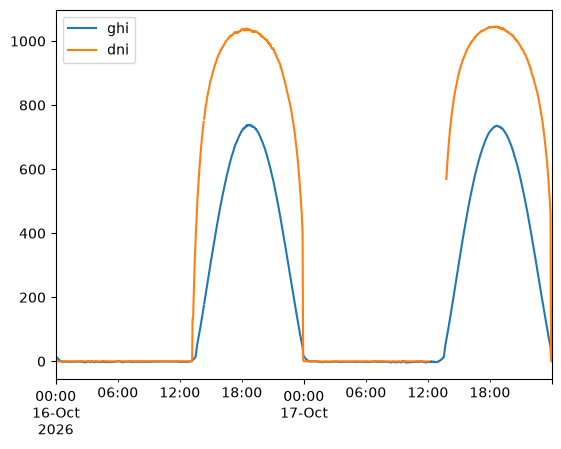

In [6]:
obs[['ghi', 'dni']].plot()

In [7]:
# list of dates
dates = obs.index.normalize().unique()
dates

DatetimeIndex(['2026-10-16 00:00:00+00:00', '2026-10-17 00:00:00+00:00'], dtype='datetime64[us, UTC]', freq=None)

Now, we will forecast the first day, testing 60- and 5-minute output intervals with both IFS and GFS.

We will only look at GHI and DNI, ignoring DHI. We will calculate mean absolute error (MAE) for hourly DNI. 

## IFS

In [8]:
model = 'ifs'
priority = 'google'
day_num = 1

# first day, 11 AM UTC (~5 AM local time)
available_date = dates[day_num-1]+pd.Timedelta(hours=11)

init_date, run_length, lead_time_to_start = hefty.utilities.adjust_forecast_datetimes(
    available_date=available_date,
    run_length_needed=18,
    lead_time_to_start_needed=0,
    model=model
)

resource_ifs = hefty.solar.get_solar_forecast_fast(
    latitude=metadata['latitude'],
    longitude=metadata['longitude'],
    init_date=init_date,
    run_length=run_length,
    lead_time_to_start=lead_time_to_start,
    model=model,
    priority=priority,
    output_interval=60
)

In [9]:
resource_ifs_5min = hefty.solar.get_solar_forecast_fast(
    latitude=metadata['latitude'],
    longitude=metadata['longitude'],
    init_date=init_date,
    run_length=run_length,
    lead_time_to_start=lead_time_to_start,
    model=model,
    priority=priority,
    output_interval=5
)

# resample to 60-minute for comparison
resource_ifs_5min_resampled = resource_ifs_5min.resample('60min').mean()
resource_ifs_5min_resampled.index = resource_ifs_5min_resampled.index + pd.Timedelta('30min')

### Results

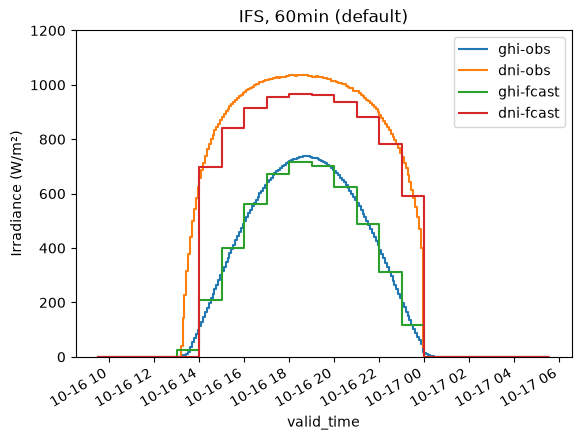

In [10]:
fcast = resource_ifs.copy()

# calculate 5min avg obs, plot obs and fcast
obs_5min = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('5min').mean()
obs_5min.index = obs_5min.index + pd.Timedelta('2.5min')
obs_5min['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_5min['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('IFS, 60min (default)')
plt.show()

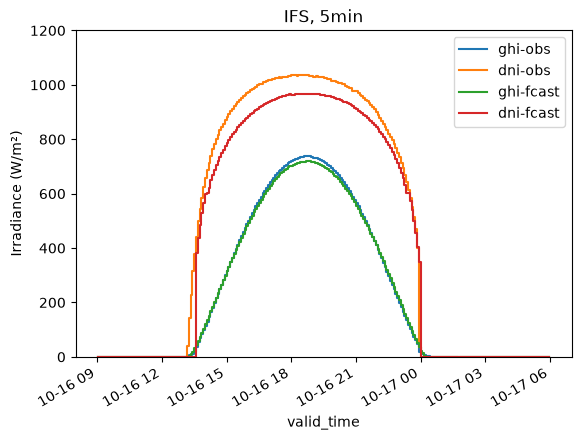

In [11]:
fcast = resource_ifs_5min.copy()

# calculate 5min avg obs, plot obs and fcast
obs_5min = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('5min').mean()
obs_5min.index = obs_5min.index + pd.Timedelta('2.5min')
obs_5min['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_5min['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('IFS, 5min')
plt.show()

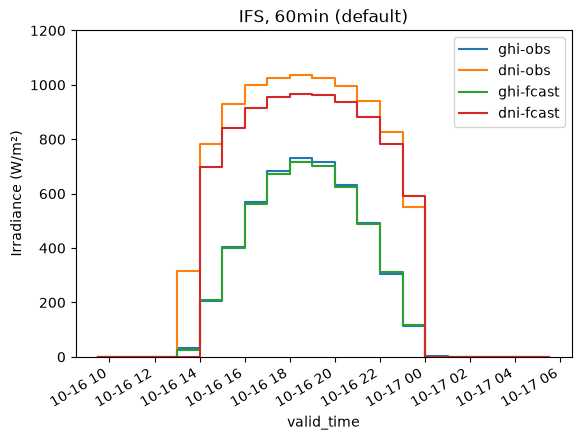

60min DNI MAE: 46.618406820438636 W/m²


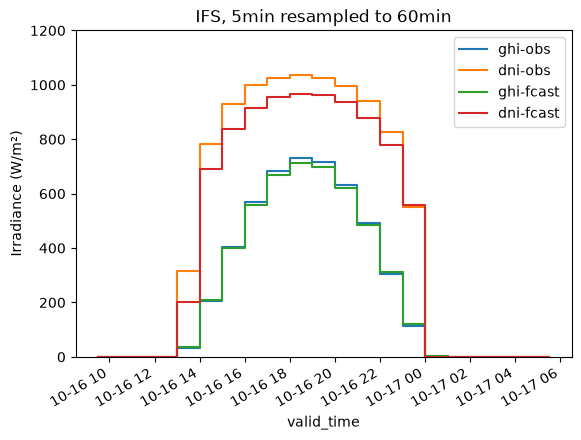

5min DNI MAE: 36.55529554748728 W/m²


In [12]:
fcast = resource_ifs.copy()

# calculate hourly avg obs, plot obs and fcast
obs_1h = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('1h').mean()
obs_1h.index = obs_1h.index + pd.Timedelta('30min')
obs_1h['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_1h['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('IFS, 60min (default)')
plt.show()

# DNI error
mae = np.mean(np.abs(obs_1h['dni'] - fcast['dni']))
print(f'60min DNI MAE: {mae} W/m²')

fcast = resource_ifs_5min_resampled.copy()

# calculate hourly avg obs, plot obs and fcast
obs_1h = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('1h').mean()
obs_1h.index = obs_1h.index + pd.Timedelta('30min')
obs_1h['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_1h['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('IFS, 5min resampled to 60min')
plt.show()

# DNI error
mae = np.mean(np.abs(obs_1h['dni'] - fcast['dni']))
print(f'5min DNI MAE: {mae} W/m²')

## GFS

In [13]:
model = 'gfs'
priority = 'aws'
day_num = 1

# first day, 11 AM UTC (~5 AM local time)
available_date = dates[day_num-1]+pd.Timedelta(hours=11)

init_date, run_length, lead_time_to_start = hefty.utilities.adjust_forecast_datetimes(
    available_date=available_date,
    run_length_needed=18,
    lead_time_to_start_needed=0,
    model=model
)

resource_gfs = hefty.solar.get_solar_forecast_fast(
    latitude=metadata['latitude'],
    longitude=metadata['longitude'],
    init_date=init_date,
    run_length=run_length,
    lead_time_to_start=lead_time_to_start,
    model=model,
    priority=priority,
    output_interval=60
)

In [14]:
resource_gfs_5min = hefty.solar.get_solar_forecast_fast(
    latitude=metadata['latitude'],
    longitude=metadata['longitude'],
    init_date=init_date,
    run_length=run_length,
    lead_time_to_start=lead_time_to_start,
    model=model,
    priority=priority,
    output_interval=5
)

# resample to 60-minute for comparison
resource_gfs_5min_resampled = resource_gfs_5min.resample('60min').mean()
resource_gfs_5min_resampled.index = resource_gfs_5min_resampled.index + pd.Timedelta('30min')

### Results

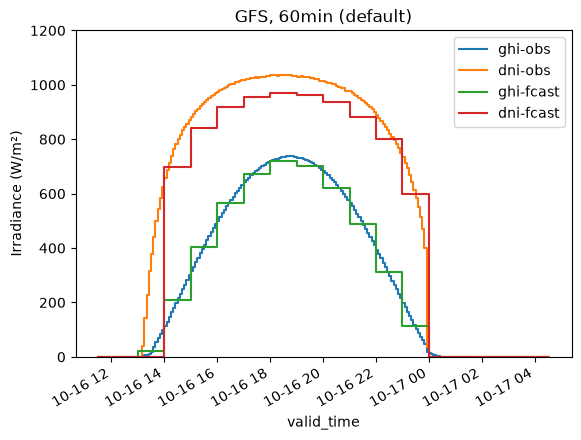

In [15]:
fcast = resource_gfs.copy()

# calculate 5min avg obs, plot obs and fcast
obs_5min = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('5min').mean()
obs_5min.index = obs_5min.index + pd.Timedelta('2.5min')
obs_5min['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_5min['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('GFS, 60min (default)')
plt.show()

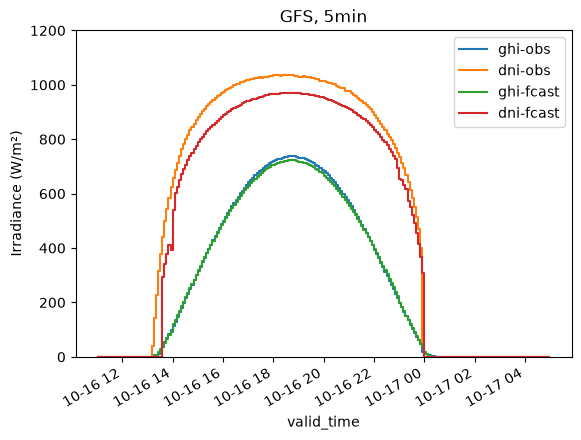

In [16]:
fcast = resource_gfs_5min.copy()

# calculate 5min avg obs, plot obs and fcast
obs_5min = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('5min').mean()
obs_5min.index = obs_5min.index + pd.Timedelta('2.5min')
obs_5min['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_5min['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('GFS, 5min')
plt.show()

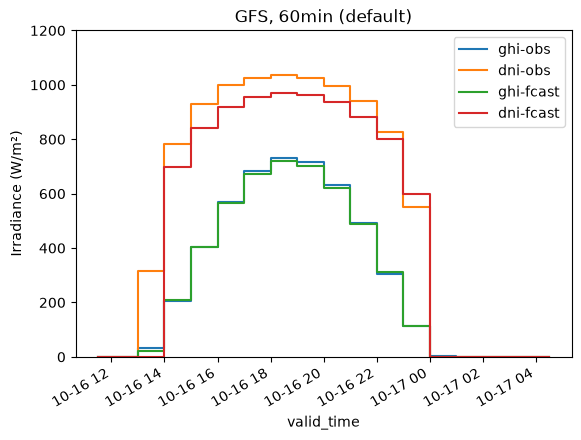

60min DNI MAE: 53.28463854911885 W/m²


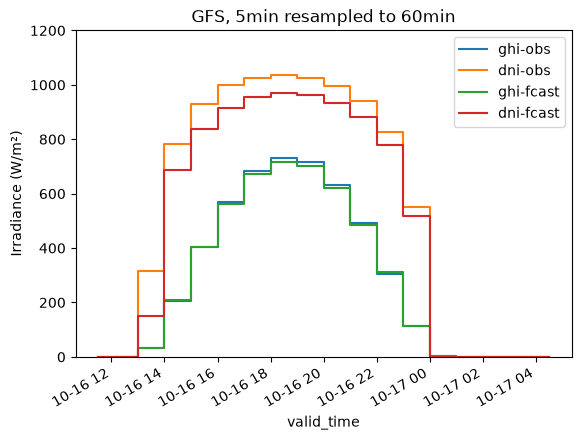

5min DNI MAE: 46.550824235288644 W/m²


In [17]:
fcast = resource_gfs.copy()

# calculate hourly avg obs, plot obs and fcast
obs_1h = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('1h').mean()
obs_1h.index = obs_1h.index + pd.Timedelta('30min')
obs_1h['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_1h['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('GFS, 60min (default)')
plt.show()

# DNI error
mae = np.mean(np.abs(obs_1h['dni'] - fcast['dni']))
print(f'60min DNI MAE: {mae} W/m²')

fcast = resource_gfs_5min_resampled.copy()

# calculate hourly avg obs, plot obs and fcast
obs_1h = obs[(obs.index >= fcast.index.min()) & (obs.index <= fcast.index.max())][['ghi', 'dni', 'dhi']].resample('1h').mean()
obs_1h.index = obs_1h.index + pd.Timedelta('30min')
obs_1h['ghi'].plot(drawstyle='steps-mid', label='ghi-obs')
obs_1h['dni'].plot(drawstyle='steps-mid', label='dni-obs')
fcast['ghi'].plot(drawstyle='steps-mid', label='ghi-fcast')
fcast['dni'].plot(drawstyle='steps-mid', label='dni-fcast')
plt.legend()
plt.ylim([0,1200])
plt.ylabel('Irradiance (W/m²)')
plt.title('GFS, 5min resampled to 60min')
plt.show()

# DNI error
mae = np.mean(np.abs(obs_1h['dni'] - fcast['dni']))
print(f'5min DNI MAE: {mae} W/m²')

## Conclusions

The most notable improvements are in the first and last hours of the day, particularly where sunrise/set occurs within 30 minutes of the nearest full daytime hour. 

Also notice that the bias in DNI is more consistent (more uniformely under-forecasted), which could make forecast tuning easier.

_This document/data/output/Results is/are based on data and products of the European Centre for Medium-Range Weather Forecasts (ECMWF). © 2026 European Centre for Medium-Range Weather Forecasts (ECMWF), www.ecmwf.int. This data is published under a Creative Commons Attribution 4.0 International (CC BY 4.0). https://creativecommons.org/licenses/by/4.0/. ECMWF does not accept any liability whatsoever for any error or omission in the data, their availability, or for any loss or damage arising from their use._

_ECMWF Data have been modified using the functions included in the hefty Python package (e.g., interpolation to hourly values)._